# Lab 01 - Wyszukiwanie obrazów w oparciu o deskryptory FFT

### 1) wygenerowanie obrazów

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [2]:
def generate_shapes():
    circle = np.zeros((64, 64), dtype=np.uint8)
    rectangle = np.zeros((64, 64), dtype=np.uint8)
    rombus = np.zeros((64, 64), dtype=np.uint8)
    triangle = np.zeros((64, 64), dtype=np.uint8)

    cv2.circle(circle, (32, 32), 20, 1, 3)
    cv2.rectangle(rectangle, (12, 20), (52, 44), 1, 3)

    cv2.polylines(rombus, [np.array([[32, 12], [44, 32], [32, 52], [20, 32]], dtype=np.int32)], True, 1, 3)
    cv2.polylines(triangle, [np.array([[32, 12], [52, 52], [12, 52]], dtype=np.int32)], True, 1, 3)

    return circle, rectangle, rombus, triangle

In [3]:
img_circle, img_rectangle, img_rombus, img_triangle = generate_shapes()

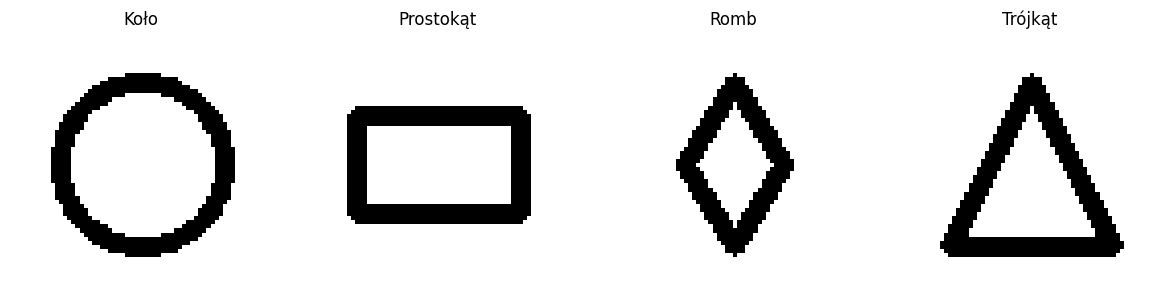

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
images = [img_circle, img_rectangle, img_rombus, img_triangle]
titles = ['Koło', 'Prostokąt', 'Romb', 'Trójkąt']

for ax, img, title in zip(axs, images, titles):
    ax.imshow(img, cmap='binary')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

### 2) transformacje i utworzenie bazy danych

In [5]:
def apply_transformation(img):
    transformed = []
    rows, cols = img.shape

    # rotacja
    for angle in [45, 90, 135]:
        rotation_matrix = cv2.getRotationMatrix2D((cols / 2, rows / 2), angle, 1)
        rotated_img = cv2.warpAffine(img, rotation_matrix, (cols, rows))
        transformed.append(rotated_img)

    # skalowanie i ściananie
    shear_matrix = np.float32([[1, 0.4, -10], 
                               [0, 1,   0]])
    affine_img = cv2.warpAffine(img, shear_matrix, (cols, rows))
    transformed.append(affine_img)

    shear_matrix2 = np.float32([[1, 0.1, -10], 
                                [0, 0.6,   0]])
    affine_img2 = cv2.warpAffine(img, shear_matrix2, (cols, rows))
    transformed.append(affine_img2)

    # translacja
    translation_matrix = np.float32([[1, 0, 10], [0, 1, -10]])
    translated_img = cv2.warpAffine(img, translation_matrix, (cols, rows))
    transformed.append(translated_img)

    return transformed

In [6]:
def create_dataset(images, labels):
    data = []

    for img, label in zip(images, labels):
        data.append({"image": img, "label": label})

        transformed_images = apply_transformation(img)
        for transformed_img in transformed_images:
            data.append({"image": transformed_img, "label": label})
    return data

In [7]:
dataset = create_dataset(images, titles)

len(dataset)

28

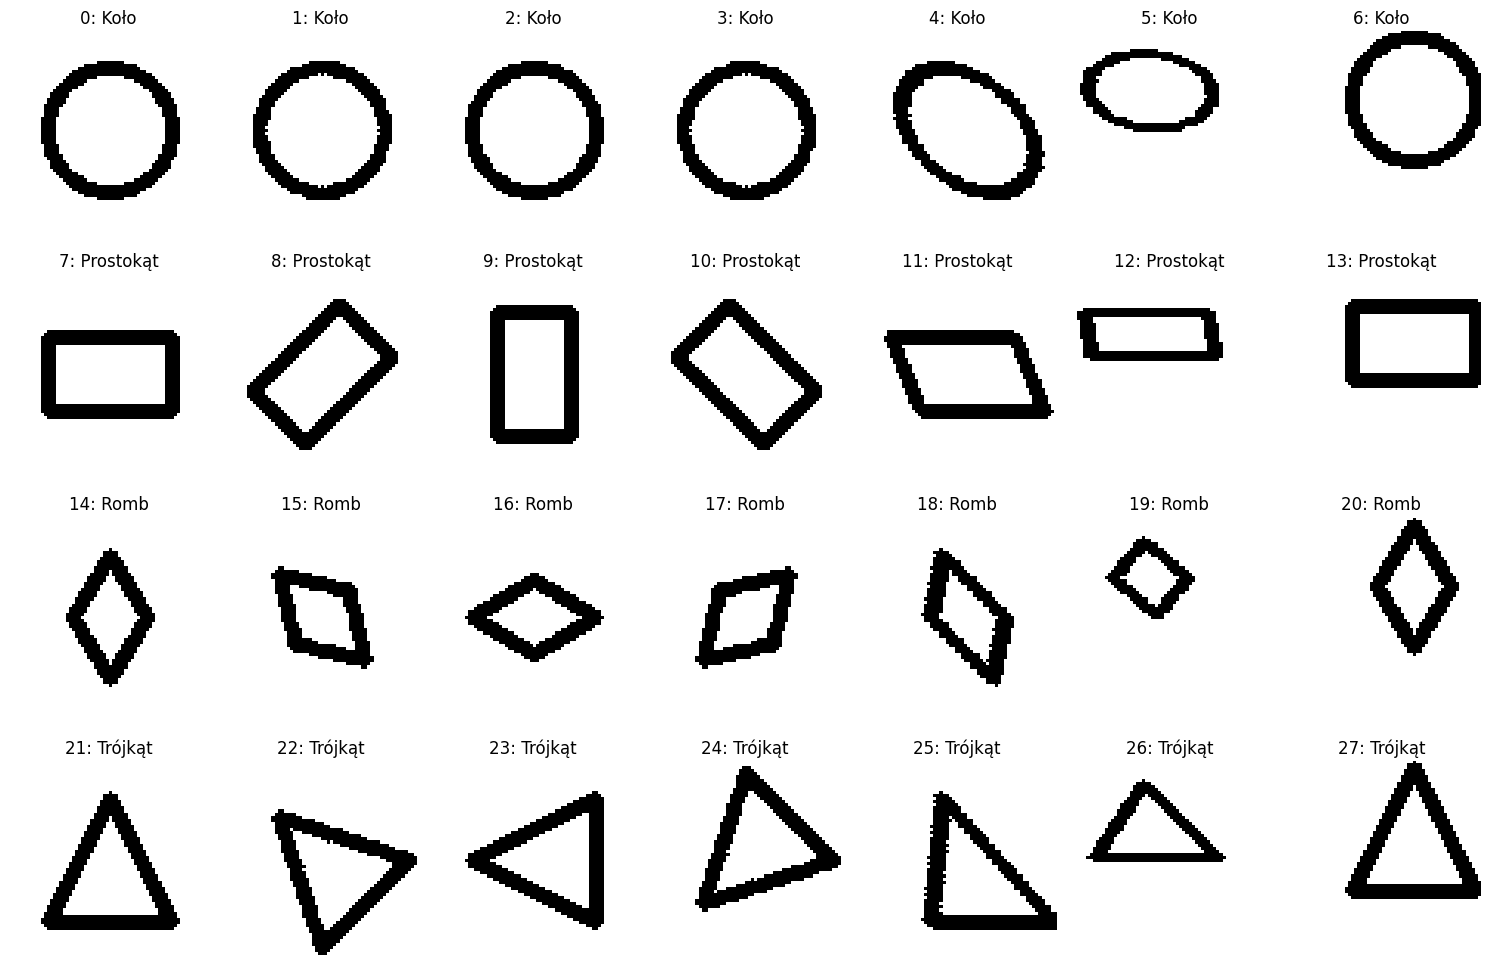

In [8]:
fig, axs = plt.subplots(4, 7, figsize=(15, 10))
axs = axs.flatten()

for i, item in enumerate(dataset):
    axs[i].imshow(item['image'], cmap='binary')
    axs[i].set_title(f"{i}: {item['label']}")
    axs[i].axis('off')

plt.tight_layout()
plt.show()

### 3) obrazy typu query

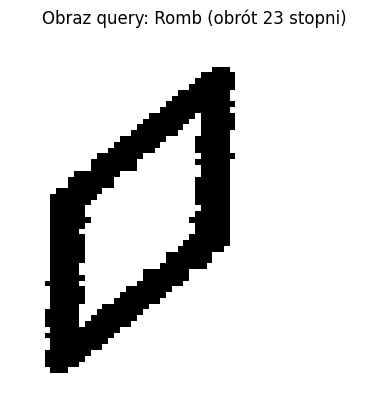

In [9]:
query_base_img = img_rombus
query_label_true = 'Romb'

rows, cols = query_base_img.shape
rot_matrix_query = cv2.getRotationMatrix2D((cols / 2, rows / 2), -23, 1)
query_image = cv2.warpAffine(query_base_img, rot_matrix_query, (cols, rows))

shear_matrix = np.float32([[1.2, -0.2, -10], 
                            [-0.2, 1.2,   0]])
query_image = cv2.warpAffine(query_image, shear_matrix, (cols, rows))

plt.imshow(query_image, cmap='binary')
plt.title(f"Obraz query: {query_label_true} (obrót 23 stopni)")
plt.axis('off')
plt.show()

### 4) wyznaczenie deskryptorów ftt

In [10]:
def get_fft_descriptor(img, crop_size=16):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = np.abs(fshift)

    rows, cols = img.shape
    center_row, center_col = rows // 2, cols // 2
    half_crop = crop_size // 2

    descriptor = magnitude_spectrum[center_row - half_crop:center_row + half_crop,
                                    center_col - half_crop:center_col + half_crop]
    return descriptor

In [11]:
for item in dataset:
    item['descriptor'] = get_fft_descriptor(item['image'])

### 5) deskryptor dla obrazu wejściowego

In [12]:
query_descriptor = get_fft_descriptor(query_image)

### 6) klasyfikacja najpodobniejszych obrazów - euklidesowa odległość

In [13]:
def find_best_match(query_desc, db):
    min_distance = float('inf')
    best_match = None
    
    q_vec = query_desc.flatten()
    
    for item in db:
        db_vec = item['descriptor'].flatten()
        
        dist = np.linalg.norm(q_vec - db_vec)
        
        if dist < min_distance:
            min_distance = dist
            best_match = item
            
    return best_match, min_distance

In [14]:
best_match, distance = find_best_match(query_descriptor, dataset)

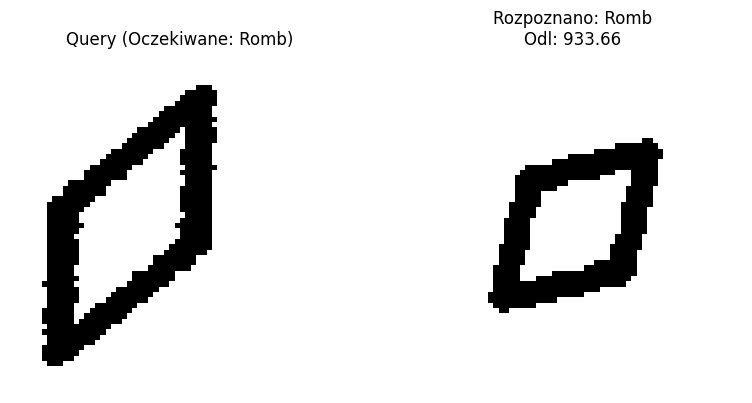

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

axs[0].imshow(query_image, cmap='binary')
axs[0].set_title(f"Query (Oczekiwane: {query_label_true})")
axs[0].axis('off')

axs[1].imshow(best_match['image'], cmap='binary')
axs[1].set_title(f"Rozpoznano: {best_match['label']}\nOdl: {distance:.2f}")
axs[1].axis('off')

plt.tight_layout()
plt.show()